<a href="https://colab.research.google.com/github/ethereal-arko/Heart_Disease_Prediction/blob/main/Heart_Disease_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Heart Disease Prediction Using Logistic Regression

## Project Overview

Heart disease is one of the major causes of death worldwide. Machine learning can help identify patterns in patient data and estimate the likelihood of heart disease.

In this project, a Logistic Regression model is developed to predict whether a person has heart disease based on selected clinical features.

## Objectives

- Explore and understand the heart disease dataset.
- Perform exploratory data analysis (EDA).
- Prepare the data for machine learning.
- Train a Logistic Regression classification model.
- Evaluate model performance using appropriate classification metrics.
- Build a simple predictive system for new input data.

## Problem Statement

This is a **binary classification problem**.

- **Target = 1:** Heart disease is indicated by the dataset label.
- **Target = 0:** Heart disease is not indicated by the dataset label.

The model's predictions are for educational purposes and are not a substitute for professional medical diagnosis.



## 2. Importing Libraries

The following Python libraries are used for data manipulation, numerical operations, data visualization, and machine learning.


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    RocCurveDisplay
)

print("All libraries imported successfully!")


All libraries imported successfully!



## 3. Loading the Dataset

The dataset is loaded into a Pandas DataFrame using `pd.read_csv()`. A DataFrame allows us to inspect, analyze, and preprocess the dataset before training the machine learning model.


In [25]:
dataset_url = "https://raw.githubusercontent.com/ethereal-arko/Heart_Disease_Prediction/main/heart_disease_data.csv"

heart_data = pd.read_csv(dataset_url)

print("Dataset loaded successfully!")
print("Dataset shape:", heart_data.shape)

heart_data.head()

Dataset loaded successfully!
Dataset shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [3]:

# Check the number of rows and columns
print("Dataset shape:", heart_data.shape)


Dataset shape: (303, 14)



## 4. Understanding the Dataset

Before building a machine learning model, it is important to understand the dataset's structure, data types, missing values, and statistical properties. This helps identify potential data quality issues before preprocessing.


In [4]:

# Display dataset information
heart_data.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB


In [5]:

# Count missing values in each column
print("Missing values in each column:")
print(heart_data.isnull().sum())


Missing values in each column:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64


In [6]:

# Generate descriptive statistics
heart_data.describe()


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.366337,0.683168,0.966997,131.623762,246.264026,0.148515,0.528053,149.646865,0.326733,1.039604,1.399340,0.729373,2.313531,0.544554
std,9.082101,0.466011,1.032052,17.538143,51.830751,0.356198,0.525860,22.905161,0.469794,1.161075,0.616226,1.022606,0.612277,0.498835
min,29.000000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,47.500000,0.000000,0.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,55.000000,1.000000,1.000000,130.000000,240.000000,0.000000,1.000000,153.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,274.500000,0.000000,1.000000,166.000000,1.000000,1.600000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000



## 5. Exploratory Data Analysis (EDA)

Exploratory Data Analysis (EDA) helps us understand the distribution of the target variable, identify potential data quality issues, and explore relationships between input features and the target before training the model.


In [7]:

# Count the samples in each target class
print("Target distribution:")
print(heart_data['target'].value_counts().sort_index())

# Calculate class percentages
print("\nTarget percentage:")
print((heart_data['target'].value_counts(normalize=True).sort_index() * 100).round(2))


Target distribution:
target
0    138
1    165
Name: count, dtype: int64

Target percentage:
target
0    45.54
1    54.46
Name: proportion, dtype: float64


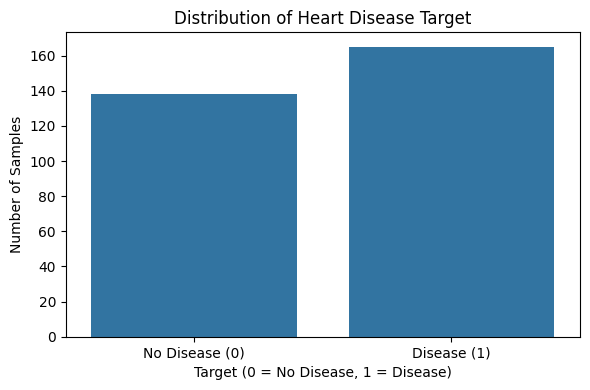

In [8]:

# Plot the target class distribution
plt.figure(figsize=(6, 4))

sns.countplot(data=heart_data, x='target')

plt.title('Distribution of Heart Disease Target')
plt.xlabel('Target (0 = No Disease, 1 = Disease)')
plt.ylabel('Number of Samples')
plt.xticks([0, 1], ['No Disease (0)', 'Disease (1)'])
plt.tight_layout()
plt.show()


In [9]:

# Check for duplicate rows
duplicate_count = heart_data.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)


Number of duplicate rows: 1



### 5.4. Checking Duplicate Records

Duplicate records may cause repeated samples to receive additional weight during model training. We inspect duplicate rows before deciding whether to remove them.


In [10]:

# Display duplicate rows
duplicate_rows = heart_data[heart_data.duplicated(keep=False)]

print("Duplicate records:")
display(duplicate_rows)


Duplicate records:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
163,38,1,2,138,175,0,1,173,0,0.0,2,4,2,1
164,38,1,2,138,175,0,1,173,0,0.0,2,4,2,1



### 5.5. Correlation Analysis

Correlation analysis measures the strength and direction of linear association between numerical variables. A heatmap provides a visual summary of these relationships.

Correlation does not establish causation, and the numerical encoding of categorical features can affect how their correlations should be interpreted.


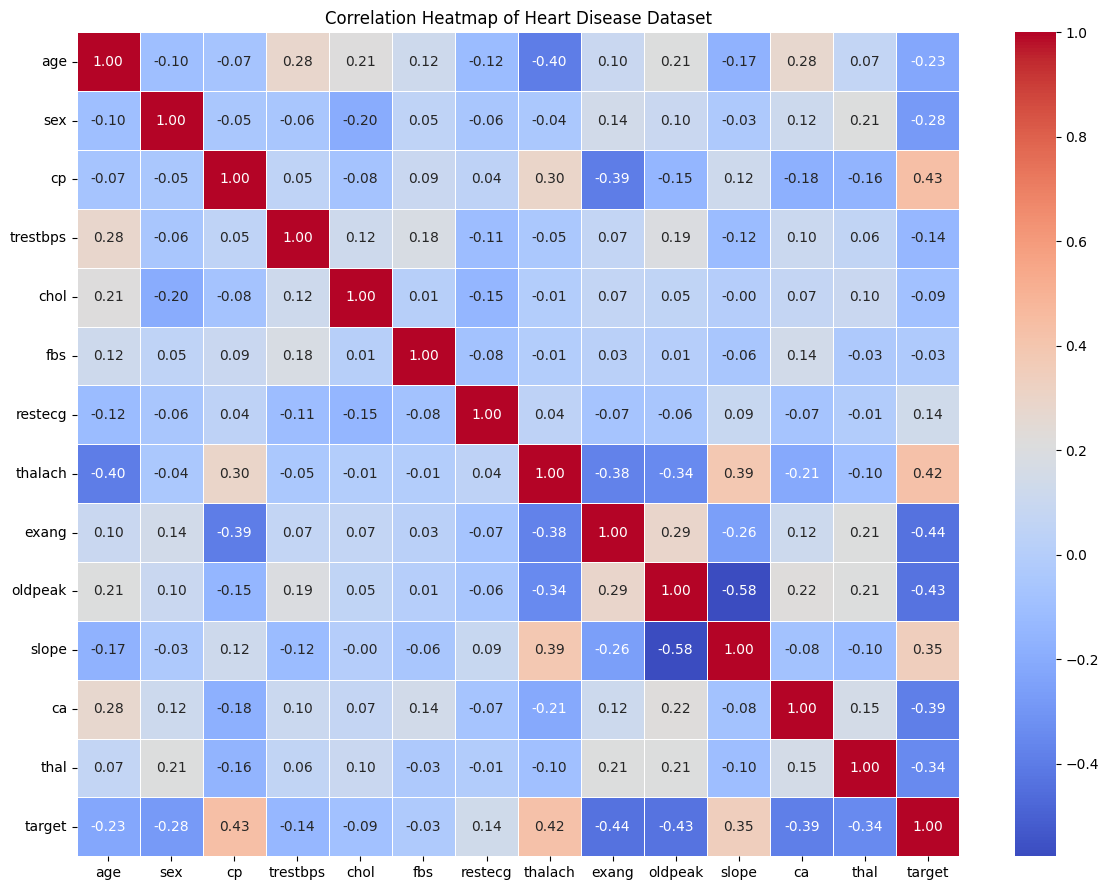

In [13]:

# Calculate the correlation matrix
correlation_matrix = heart_data.corr(numeric_only=True)

# Visualize the correlations
plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Heart Disease Dataset')
plt.tight_layout()
plt.show()



### 5.6. Removing Duplicate Records

The dataset contains one exact duplicate record. Duplicate rows are removed to avoid counting the same observation more than once during model development.


In [14]:

# Remove exact duplicate rows
heart_data = heart_data.drop_duplicates().reset_index(drop=True)

print("Dataset shape after removing duplicates:", heart_data.shape)
print("Remaining duplicate rows:", heart_data.duplicated().sum())


Dataset shape after removing duplicates: (302, 14)
Remaining duplicate rows: 0


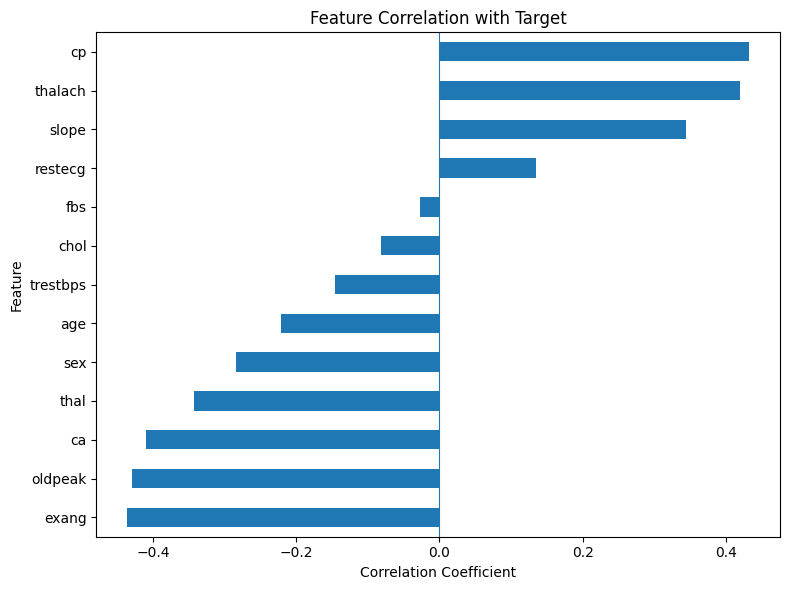

In [15]:

# Sort feature correlations with the target
target_correlation = (
    heart_data.corr(numeric_only=True)['target']
    .drop('target')
    .sort_values()
)

plt.figure(figsize=(8, 6))

target_correlation.plot(kind='barh')

plt.title('Feature Correlation with Target')
plt.xlabel('Correlation Coefficient')
plt.ylabel('Feature')
plt.axvline(0, linewidth=0.8)
plt.tight_layout()
plt.show()



## 6. Data Preprocessing

Data preprocessing prepares the dataset for machine learning. In this section, we separate the input features from the target variable and split the data into training and testing sets.

### 6.1. Separating Features and Target

The input features (`X`) contain the information used by the model to make predictions. The target variable (`y`) contains the class labels that the model learns to predict.


In [16]:

# Separate input features and target variable
X = heart_data.drop(columns='target')
y = heart_data['target']

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nFeature columns:")
print(X.columns.tolist())


Features shape: (302, 13)
Target shape: (302,)

Feature columns:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']



### 6.2. Splitting Data into Training and Testing Sets

The dataset is divided into training and testing subsets. The training set is used to fit the model, while the testing set evaluates its performance on unseen data.

An 80:20 split is used. Stratification preserves approximately the same target-class proportions in both subsets.


In [17]:

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting target distribution:")
print(y_test.value_counts().sort_index())


Training features: (241, 13)
Testing features: (61, 13)

Training target distribution:
target
0    110
1    131
Name: count, dtype: int64

Testing target distribution:
target
0    28
1    33
Name: count, dtype: int64



### 6.3. Feature Scaling and Pipeline

StandardScaler transforms numerical features to have approximately zero mean and unit variance. This helps Logistic Regression optimize its coefficients effectively.

A Scikit-learn Pipeline combines scaling and model training into one workflow. During fitting, the scaler learns its parameters only from the training data, helping prevent data leakage from the test set.


In [18]:

# Create a pipeline with feature scaling and Logistic Regression
model = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(max_iter=1000))
])

print("Pipeline created successfully!")


Pipeline created successfully!



## 7. Model Training

Logistic Regression is a supervised machine learning algorithm used for classification. It estimates the probability that an input belongs to a particular class and assigns a class label based on a decision threshold.

In this project, the model learns patterns from the training data to classify whether heart disease is indicated by the dataset's target label.


In [19]:

# Train the Logistic Regression pipeline
model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")


Logistic Regression model trained successfully!



## 8. Model Evaluation

Model evaluation measures how well a trained machine learning model performs. We evaluate the model on both training and testing data to understand its performance and generalization to unseen samples.

### 8.1. Training and Testing Accuracy

Accuracy is the proportion of correctly classified samples among all evaluated samples. Comparing training and testing accuracy can help identify potential overfitting, although accuracy alone does not describe every aspect of classification performance.


In [20]:

# Predictions on training data
y_train_pred = model.predict(X_train)

# Predictions on testing data
y_test_pred = model.predict(X_test)

# Calculate accuracy
training_accuracy = accuracy_score(y_train, y_train_pred)
testing_accuracy = accuracy_score(y_test, y_test_pred)

print(f"Training Accuracy: {training_accuracy:.4f}")
print(f"Testing Accuracy:  {testing_accuracy:.4f}")


Training Accuracy: 0.8548
Testing Accuracy:  0.7869



### 8.2. Classification Report

The classification report summarizes precision, recall, and F1-score for each class.

- **Precision:** Among samples predicted as a class, the proportion that truly belongs to that class.
- **Recall:** Among actual samples of a class, the proportion correctly identified by the model.
- **F1-score:** The harmonic mean of precision and recall.
- **Support:** The number of actual samples belonging to each class.


In [21]:

# Display classification metrics for the test set
print("Classification Report:\n")
print(classification_report(
    y_test,
    y_test_pred,
    target_names=['No Disease (0)', 'Disease (1)'],
    zero_division=0
))


Classification Report:

                precision    recall  f1-score   support

No Disease (0)       0.83      0.68      0.75        28
   Disease (1)       0.76      0.88      0.82        33

      accuracy                           0.79        61
     macro avg       0.79      0.78      0.78        61
  weighted avg       0.79      0.79      0.78        61




### 8.3. Confusion Matrix

A confusion matrix compares actual class labels with predicted labels.

- **True Negative (TN):** Actual 0, predicted 0.
- **False Positive (FP):** Actual 0, predicted 1.
- **False Negative (FN):** Actual 1, predicted 0.
- **True Positive (TP):** Actual 1, predicted 1.


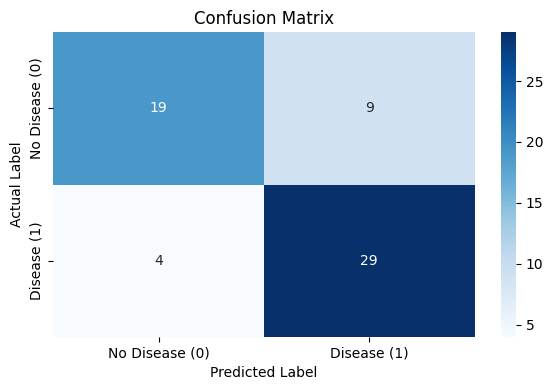

Confusion Matrix:
 [[19  9]
 [ 4 29]]


In [22]:

# Calculate and visualize the confusion matrix
cm = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Disease (0)', 'Disease (1)'],
    yticklabels=['No Disease (0)', 'Disease (1)']
)

plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.tight_layout()
plt.show()

print("Confusion Matrix:\n", cm)



### 8.4. ROC Curve and AUC

The ROC curve shows the relationship between the true positive rate and false positive rate across different classification thresholds.

The Area Under the ROC Curve (ROC-AUC) measures how well the model ranks positive samples above negative samples. A value closer to 1 indicates better discrimination, while a value near 0.5 indicates performance similar to random ranking.


ROC-AUC Score: 0.8647


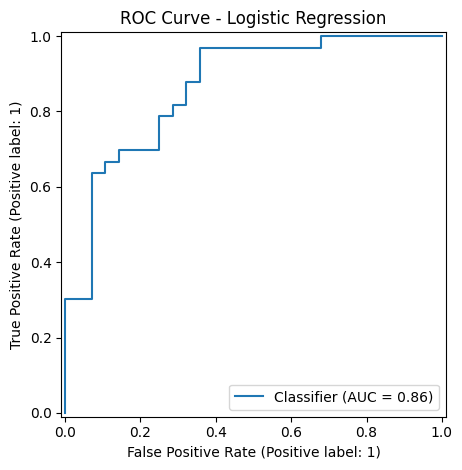

In [23]:

# Predict probabilities for the positive class
y_test_proba = model.predict_proba(X_test)[:, 1]

# Calculate ROC-AUC
roc_auc = roc_auc_score(y_test, y_test_proba)
print(f"ROC-AUC Score: {roc_auc:.4f}")

# Plot the ROC curve
RocCurveDisplay.from_predictions(y_test, y_test_proba)
plt.title('ROC Curve - Logistic Regression')
plt.tight_layout()
plt.show()



### 8.5. Baseline Model Summary

The Logistic Regression model achieved a training accuracy of 85.48% and a testing accuracy of 78.69%. Its ROC-AUC score was 0.8647.

For the positive class (target = 1), the model achieved a recall of approximately 87.88% and an F1-score of 0.82 (rounded in the classification report).

The difference between training and testing accuracy suggests that the model performs somewhat better on the training data. Further validation would be required to assess the stability and generalization of its performance.

These results are based on a single train-test split of a small dataset and should not be interpreted as evidence of clinical diagnostic performance.



## 9. Building a Predictive System

The trained model can be used to generate predictions for new samples. The input must contain the same features, in the same order, as the data used during model training.

The output represents the model's predicted dataset label, not a confirmed medical diagnosis.


In [24]:

# Example input data using the dataset's feature order
input_data = (41, 0, 1, 130, 264, 0, 0, 172, 0, 1.4, 2, 0, 2)

# Convert the input into a DataFrame with the correct column names
input_df = pd.DataFrame([input_data], columns=X.columns)

# Predict the target class
prediction = model.predict(input_df)

# Predict the probability of target = 1
disease_probability = model.predict_proba(input_df)[0, 1]

print("Predicted target:", prediction[0])
print(f"Estimated probability for target = 1: {disease_probability:.2%}")

if prediction[0] == 1:
    print("The model predicts: Heart disease indicated by the dataset label.")
else:
    print("The model predicts: No heart disease indicated by the dataset label.")


Predicted target: 1
Estimated probability for target = 1: 92.18%
The model predicts: Heart disease indicated by the dataset label.



## 10. Conclusion

In this project, a Logistic Regression model was developed to predict heart disease labels using a dataset containing 303 original records and 13 input features. One exact duplicate record was removed, leaving 302 records for model development.

The dataset was explored through descriptive statistics, target distribution analysis, duplicate checking, and correlation analysis. The data was then divided into training and testing sets using stratified sampling. StandardScaler and Logistic Regression were combined in a Pipeline to reduce the risk of data leakage.

The model achieved a training accuracy of 85.48%, a testing accuracy of 78.69%, and a ROC-AUC score of 0.8647. For the positive class, the model achieved a recall of approximately 87.88% and an F1-score of approximately 0.82.

A simple predictive system was also implemented to generate a class prediction and estimated probability for a new input sample.

Overall, this project demonstrates a complete basic machine learning workflow, from data exploration and preprocessing to model training, evaluation, and prediction.



## 11. Limitations and Future Improvements

### Limitations

- The dataset contains only 302 unique records after duplicate removal, which limits the conclusions that can be drawn from the results.
- Evaluation was performed using a single train-test split; performance may vary with a different split.
- The model's results depend on the quality, representativeness, and encoding of the dataset.
- Accuracy and ROC-AUC alone do not establish clinical usefulness or reliability.
- The predicted probability is not a clinically calibrated estimate of an individual's actual disease risk.
- This educational model is not intended for medical diagnosis or treatment decisions.

### Future Improvements

- Use stratified cross-validation to obtain more robust performance estimates.
- Compare Logistic Regression with models such as Support Vector Machine, Decision Tree, and Random Forest.
- Tune hyperparameters using cross-validation.
- Evaluate calibration and threshold-dependent metrics.
- Validate the model on an independent, representative dataset before considering any real-world application.
